Dataset records used: 1250

========== SHA-256 ==========
Records hashed: 1250
Example hash: 2388cd362b1d14f207ea91b4ccb197129929da14c906915ddd8d27ce231d25f1

========== MERKLE TREE ==========
Merkle Root: 42f4e4c3eebe2798f0c01b1cf55ee623034c0b45a9bfcb7e04ae0a72ab6cdfc9
Merkle Verified: True

========== BLOCKCHAIN ==========
Number of blocks: 3
Blockchain Valid: True

Block 0
Merkle Root: 42f4e4c3eebe2798f0c01b1cf55ee623034c0b45a9bfcb7e04ae0a72ab6cdfc9
Previous Hash: 0000000000000000000000000000000000000000000000000000000000000000
Block Hash: b396a5bcb7ebec1bf07ca8272a2e1b355b536bd9dbfcf4fd26dced4f0ca1e121

Block 1
Merkle Root: 42f4e4c3eebe2798f0c01b1cf55ee623034c0b45a9bfcb7e04ae0a72ab6cdfc9
Previous Hash: b396a5bcb7ebec1bf07ca8272a2e1b355b536bd9dbfcf4fd26dced4f0ca1e121
Block Hash: 5eb19a98def3e0b65e29caf77693b06a9d8d93fcbc1e7b5cc2c459da9f452aef

Block 2
Merkle Root: 42f4e4c3eebe2798f0c01b1cf55ee623034c0b45a9bfcb7e04ae0a72ab6cdfc9
Previous Hash: 5eb19a98def3e0b65e29caf77693b06a9d8d93fc

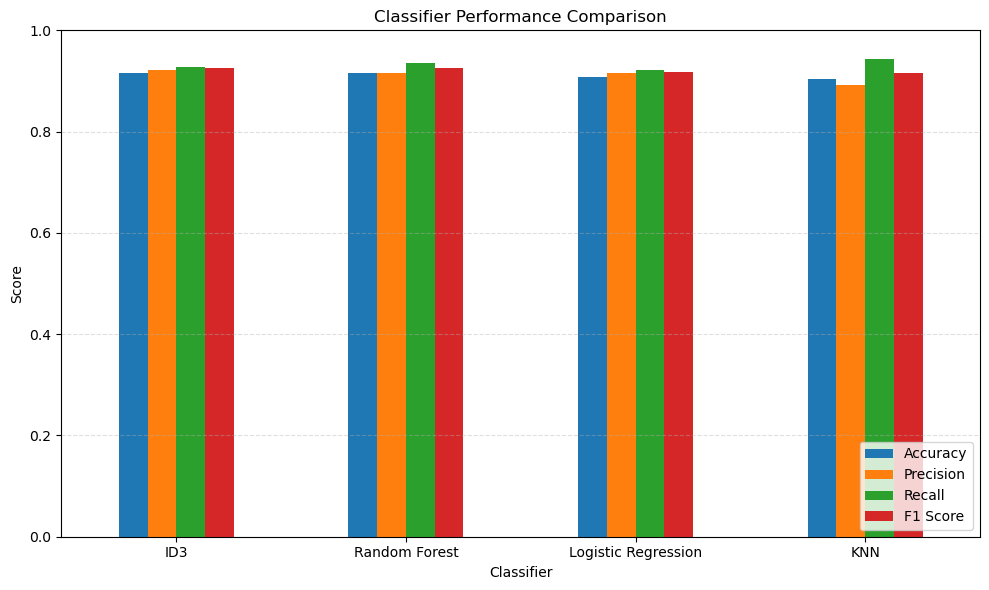

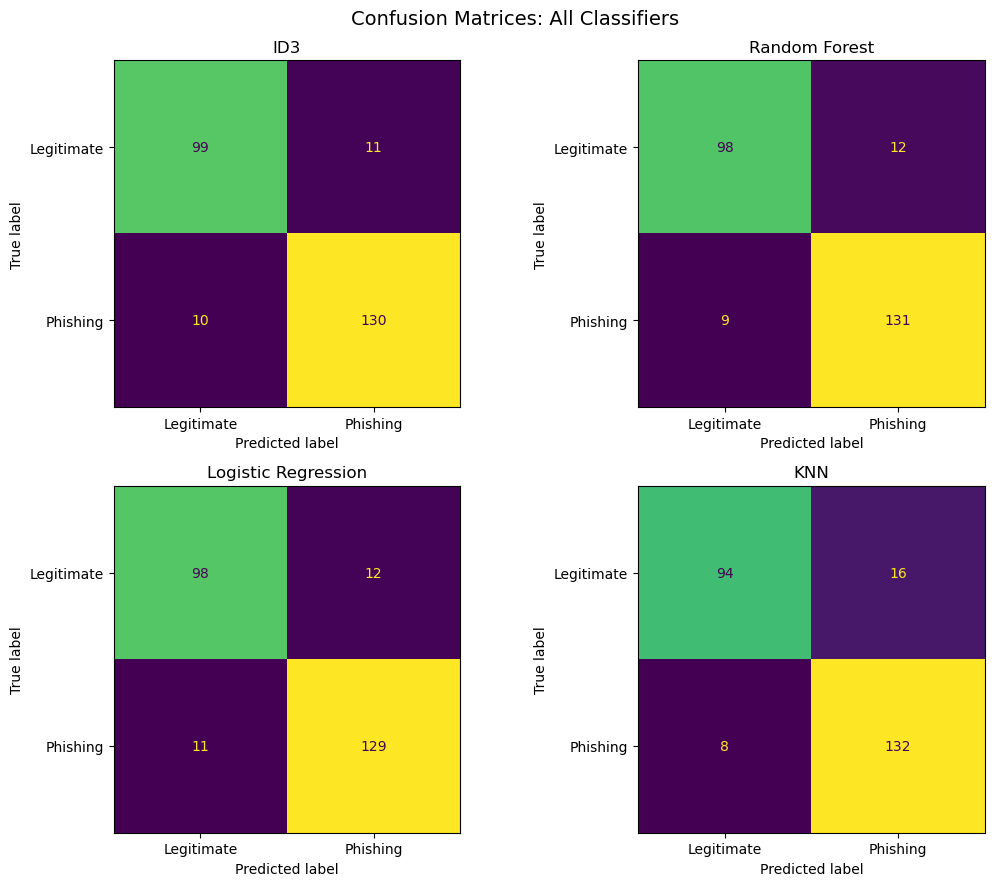

Records used: 1250


In [5]:


!pip install ucimlrepo scikit-learn pandas matplotlib -q

import hashlib
import json
import time
import math
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# 1. LOAD DATASET
dataset = fetch_ucirepo(id=379)
features = dataset.data.features.copy()
original_labels = dataset.data.targets.iloc[:, 0]

# Label 1 = phishing; label 0 = legitimate; remove suspicious records
data = features.copy()
data["label"] = original_labels.map({-1: 1, 0: None, 1: 0})
data = data.dropna().reset_index(drop=True)

X = data.drop(columns="label")
y = data["label"].astype(int)

print("Dataset records used:", len(X))


# 2. SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


# 3. ID3 CLASSIFIER
def entropy(labels):
    counts = Counter(labels)
    total = len(labels)
    return -sum(
        (count / total) * math.log2(count / total)
        for count in counts.values() if count > 0
    )


def information_gain(features, labels, feature):
    parent_entropy = entropy(labels)
    weighted_entropy = 0

    for value in features[feature].unique():
        subset = labels[features[feature] == value]
        weighted_entropy += len(subset) / len(labels) * entropy(subset)

    return parent_entropy - weighted_entropy


class Node:
    def __init__(self, feature=None, prediction=None):
        self.feature = feature
        self.prediction = prediction
        self.children = {}


def build_id3(features, labels, available_features, depth=0, max_depth=6):
    if labels.nunique() == 1:
        return Node(prediction=int(labels.iloc[0]))

    if not available_features or depth >= max_depth:
        return Node(prediction=int(labels.mode().iloc[0]))

    best_feature = max(
        available_features,
        key=lambda f: information_gain(features, labels, f)
    )
    node = Node(feature=best_feature)
    remaining = [f for f in available_features if f != best_feature]

    for value in features[best_feature].unique():
        mask = features[best_feature] == value
        node.children[value] = build_id3(
            features.loc[mask], labels.loc[mask], remaining,
            depth + 1, max_depth
        )

    return node


def predict_id3(node, row):
    if node.prediction is not None:
        return node.prediction

    value = row[node.feature]
    if value not in node.children:
        return 0

    return predict_id3(node.children[value], row)


tree = build_id3(
    X_train.reset_index(drop=True),
    y_train.reset_index(drop=True),
    list(X_train.columns)
)
id3_predictions = [
    predict_id3(tree, row) for _, row in X_test.iterrows()
]


# 4. TRAIN CLASSIFIERS FOR LATER COMPARISON
models = {
    "ID3": None,
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

predictions = {"ID3": id3_predictions}

for name, model in models.items():
    if name == "ID3":
        continue
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)


# Prepare comparison metrics now; display them at the end
results = []
for name, predicted in predictions.items():
    results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1 Score": f1_score(y_test, predicted, zero_division=0)
    })

comparison = pd.DataFrame(results)


# ============================================================
# 5. SHA-256 HASHING
# ============================================================
def sha256(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def hash_record(row):
    row_text = "|".join(map(str, row))
    return sha256(row_text)


record_hashes = X.apply(hash_record, axis=1).tolist()
example_hash = record_hashes[0]


# ============================================================
# 6. MERKLE TREE
# ============================================================
def merkle_root(hashes):
    level = list(hashes)

    if not level:
        return None

    while len(level) > 1:
        if len(level) % 2 == 1:
            level.append(level[-1])

        next_level = []
        for i in range(0, len(level), 2):
            combined = level[i] + level[i + 1]
            next_level.append(sha256(combined))
        level = next_level

    return level[0]


root = merkle_root(record_hashes)
recalculated_root = merkle_root(X.apply(hash_record, axis=1).tolist())

# 7. BLOCKCHAIN IMPLEMENTATION
def calculate_block_hash(block):
    contents = {
        "block_number": block["block_number"],
        "timestamp": block["timestamp"],
        "merkle_root": block["merkle_root"],
        "previous_hash": block["previous_hash"]
    }
    return sha256(json.dumps(contents, sort_keys=True))


def create_block(number, dataset_root, previous_hash):
    block = {
        "block_number": number,
        "timestamp": time.time(),
        "merkle_root": dataset_root,
        "previous_hash": previous_hash
    }
    block["hash"] = calculate_block_hash(block)
    return block


def verify_blockchain(chain):
    for index, block in enumerate(chain):
        if block["hash"] != calculate_block_hash(block):
            return False

        expected_previous = "0" * 64 if index == 0 else chain[index - 1]["hash"]
        if block["previous_hash"] != expected_previous:
            return False

    return True


blockchain = []
previous_hash = "0" * 64

for block_number in range(3):
    block = create_block(block_number, root, previous_hash)
    blockchain.append(block)
    previous_hash = block["hash"]

original_row = X.iloc[0].copy()
changed_row = original_row.copy()
changed_row.iloc[0] = changed_row.iloc[0] + 1
sha_tampering_detected = hash_record(original_row) != hash_record(changed_row)

tampered_X = X.copy()
tampered_X.iloc[0, 0] = tampered_X.iloc[0, 0] + 1
tampered_hashes = tampered_X.apply(hash_record, axis=1).tolist()
tampered_root = merkle_root(tampered_hashes)
merkle_tampering_detected = root != tampered_root

tampered_chain = [block.copy() for block in blockchain]
tampered_chain[1]["merkle_root"] = "TAMPERED"
blockchain_tampering_detected = not verify_blockchain(tampered_chain)

print("\n========== SHA-256 ==========")
print("Records hashed:", len(record_hashes))
print("Example hash:", example_hash)

print("\n========== MERKLE TREE ==========")
print("Merkle Root:", root)
print("Merkle Verified:", root == recalculated_root)

print("\n========== BLOCKCHAIN ==========")
print("Number of blocks:", len(blockchain))
print("Blockchain Valid:", verify_blockchain(blockchain))

for block in blockchain:
    print("\nBlock", block["block_number"])
    print("Merkle Root:", block["merkle_root"])
    print("Previous Hash:", block["previous_hash"])
    print("Block Hash:", block["hash"])

print("\n========== TAMPERING TESTS ==========")
print("SHA-256 Hash Changed:", sha_tampering_detected)
print("Merkle Root Changed:", merkle_tampering_detected)
print("Blockchain Tampering Detected:", blockchain_tampering_detected)
print("Original Blockchain Valid:", verify_blockchain(blockchain))
print("\n========== CLASSIFIER COMPARISON ==========")
print(comparison.to_string(
    index=False,
    formatters={
        "Accuracy": "{:.4f}".format,
        "Precision": "{:.4f}".format,
        "Recall": "{:.4f}".format,
        "F1 Score": "{:.4f}".format
    }
))


# 11. COMPARISON GRAPH (AT THE END)
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
comparison.set_index("Classifier")[metrics].plot(
    kind="bar", figsize=(10, 6), ylim=(0, 1), rot=0
)
plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# 12. FOUR CONFUSION MATRICES (LAST OUTPUT)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for axis, (name, predicted) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Legitimate", "Phishing"]
    )
    display.plot(ax=axis, values_format="d", colorbar=False)
    axis.set_title(name)

plt.suptitle("Confusion Matrices: All Classifiers", fontsize=14)
plt.tight_layout()
plt.show()
print("Records used:", len(X))
